# DAMICORE quickstart: visualizing a run

Runs the pipeline from [`run_example.py`](run_example.py) against [`dataset.csv`](dataset.csv) (30 synthetic rows, 3 latent clusters; see [`make_dataset.py`](make_dataset.py)), then visualizes the result:

- the exact NCD distance matrix, as a heatmap ordered by cluster
- the Neighbor Joining tree from `tree.nwk`, as a rectangular cladogram

See [`../quickstart.md`](../quickstart.md) for the notebook form of the plain API call, and [`README.md`](README.md) for how to run this file.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from damicore import estimate, run
from tree_plot import layout, parse_newick

example_dir = Path.cwd()
csv_path = example_dir / "dataset.csv"
output_dir = example_dir / "damicore-run"

/home/lobo/github/damicore/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Run the pipeline

Same call as `run_example.py`, `split="rows"` so each of the 30 rows is one object. `run()` reuses a matching completed run in `output_dir` instead of recomputing it.

In [2]:
preview = estimate(str(csv_path), split="rows")
preview.model_dump()

{'source_kind': 'delimited',
 'source_paths': (PosixPath('/home/lobo/github/damicore/docs/examples/dataset.csv'),),
 'input_sha256': '7b55a95fa13b4752b84a1691cfeca8d73584633de0c914f2a59eb8144181b23d',
 'input_size_bytes': 4920,
 'split': 'rows',
 'object_count': 30,
 'pair_count': 435,
 'effective_workers': 4,
 'matrix_bytes': 7200,
 'tree_workspace_bytes': 7200,
 'normalized_bytes': 5280,
 'max_serialized_chunk_bytes': 5280,
 'estimated_working_memory_bytes': 33794432,
 'estimated_final_metadata_bytes': 1173856,
 'estimated_diagnostic_bytes': 0,
 'estimated_artifact_bytes': 1193792,
 'required_free_disk_bytes': 1492240,
 'available_free_disk_bytes': 194380570624,
 'within_limits': True,
 'violations': []}

In [3]:
result = run(str(csv_path), split="rows", output_dir=str(output_dir), progress=False)
result.report.model_dump()

{'status': 'completed',
 'failed_stage': None,
 'object_count': 30,
 'pair_count': 435,
 'community_count': 9,
 'cluster_count': 9,
 'effective_workers': 4,
 'csv_chunk_rows': 50000,
 'compression_chunk_bytes': 4194304,
 'pairs_per_shard': 10000,
 'matrix_bytes': 7200,
 'required_free_disk_bytes': 1492240,
 'peak_rss_bytes': 96772096,
 'ncd_min': 0.0,
 'ncd_max': 0.85,
 'ncd_out_of_range_count': 0,
 'negative_branch_count': 0,
 'modularity': 0.7078778884609023,
 'timings_seconds': {'clusterizing': 0.024522941000213905,
  'distancing': 0.41671343899997737,
  'normalizing': 0.02306084599968017,
  'total': 0.4995659579999483,
  'tree_building': 0.03526873200007685},
 'verification': {'cluster_ids': True,
  'clusters': True,
  'matrix_shape': True,
  'membership': True,
  'membership_clusters': True,
  'normalization_to_labels': True,
  'requested_communities': True,
  'tree_leaves': True},
 'warnings': [],
 'error': None}

## Distance matrix heatmap

Rows/columns are reordered by FastGreedy cluster assignment, so members of the same cluster sit adjacent -- a correct clustering should show dark blocks on the diagonal.

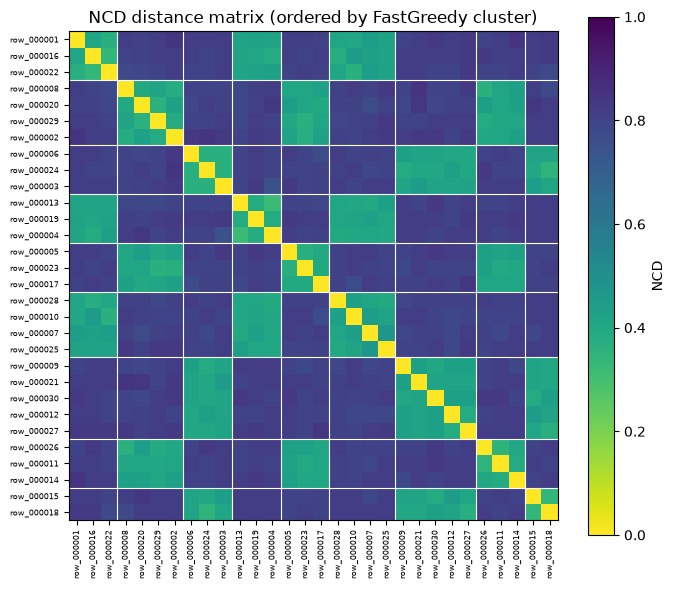

In [4]:
distance = result.distance_matrix.to_pandas()
membership = result.membership.set_index("object_id")
order = membership.sort_values("cluster").index
ordered = distance.loc[order, order]
cluster_of = membership.loc[order, "cluster"]

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(ordered.to_numpy(), cmap="viridis_r", vmin=0, vmax=1)
ax.set_xticks(range(len(order)))
ax.set_yticks(range(len(order)))
ax.set_xticklabels(order, rotation=90, fontsize=6)
ax.set_yticklabels(order, fontsize=6)
ax.set_title("NCD distance matrix (ordered by FastGreedy cluster)")
fig.colorbar(image, ax=ax, label="NCD")

# Mark cluster boundaries.
boundaries = np.flatnonzero(cluster_of.to_numpy()[1:] != cluster_of.to_numpy()[:-1]) + 0.5
for boundary in boundaries:
    ax.axhline(boundary, color="white", linewidth=0.8)
    ax.axvline(boundary, color="white", linewidth=0.8)
fig.tight_layout()

## Neighbor Joining tree

`tree_plot.py` parses `tree.nwk` (single-quoted labels, `:`-branch lengths) and lays leaves out top to bottom in tree order; x is cumulative branch length from the root. Leaf labels are colored by the same FastGreedy cluster as the heatmap above.

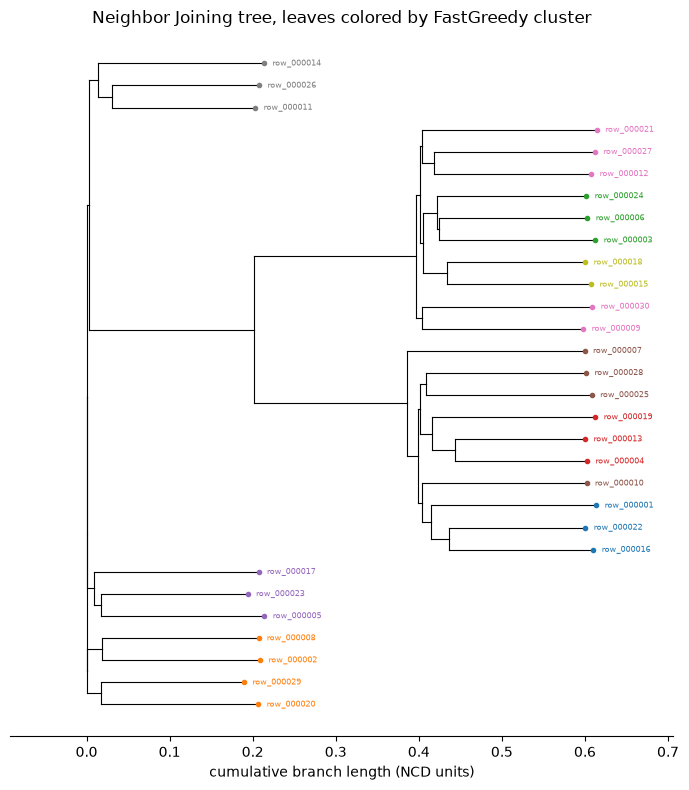

In [5]:
newick_text = (output_dir / "tree.nwk").read_text(encoding="utf-8")
root = parse_newick(newick_text)
placed, edges = layout(root)
leaves = sorted((p for p in placed if p.node.is_leaf), key=lambda p: p.y)

cluster_ids = sorted(cluster_of.unique())
palette = plt.get_cmap("tab10")
color_of_cluster = {cluster: palette(i % 10) for i, cluster in enumerate(cluster_ids)}
leaf_color = {
    p.node.name: color_of_cluster[int(membership.loc[p.node.name, "cluster"])] for p in leaves
}

fig, ax = plt.subplots(figsize=(7, 8))
for parent, child in edges:
    ax.plot([parent.x, child.x], [child.y, child.y], color="black", linewidth=0.8)
    ax.plot([parent.x, parent.x], [parent.y, child.y], color="black", linewidth=0.8)
for p in leaves:
    ax.plot(p.x, p.y, marker="o", markersize=3, color=leaf_color[p.node.name])
    ax.text(p.x + 0.01, p.y, p.node.name, fontsize=6, va="center", color=leaf_color[p.node.name])
ax.set_yticks([])
ax.set_xlabel("cumulative branch length (NCD units)")
ax.set_title("Neighbor Joining tree, leaves colored by FastGreedy cluster")
ax.margins(x=0.15)
for spine in ("top", "right", "left"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()

In [6]:
result.close()